In [1]:
%pip install ucimlrepo pandas numpy matplotlib seaborn scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 3.4 MB/s eta 0:00:03
   ------- -------------------------------- 1.6/8.4 MB 3.8 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.4 MB 5.4 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.4 MB 5.9 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.4 MB 6.1 MB/s eta 0:00:01
   -------------------------------- ------- 6.8/8.4 MB 5.4 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 5.1 MB/s eta 0:00:01
   ------------------------------------ --- 7.6/8.4 MB 4.7 MB/s eta 0:00:01
   -------------------------------------- - 8.1/8.4 MB 4.5 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 4.0 MB/s  0:00:02
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
    --------------------------------------- 0.8/37.4 MB 7.3 MB/s eta 0:00:06
   - ----------------------


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download the credit risk dataset
credit_data = fetch_ucirepo(id=144)

# Separate input features and target
X = credit_data.data.features
y = credit_data.data.targets

# Combine them into one DataFrame
df = X.copy()
df["class"] = y.iloc[:, 0]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (1000, 21)


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [3]:
# 1. Display all column names
print("Column names:")
print(df.columns.tolist())

# 2. Check the data types and missing values
print("\nDataset information:")
df.info()

# 3. Display basic statistics
print("\nNumerical summary:")
display(df.describe())

# 4. Check the target column
print("\nTarget class counts:")
print(df["class"].value_counts())

Column names:
['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20', 'class']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Attribute1   1000 non-null   str  
 1   Attribute2   1000 non-null   int64
 2   Attribute3   1000 non-null   str  
 3   Attribute4   1000 non-null   str  
 4   Attribute5   1000 non-null   int64
 5   Attribute6   1000 non-null   str  
 6   Attribute7   1000 non-null   str  
 7   Attribute8   1000 non-null   int64
 8   Attribute9   1000 non-null   str  
 9   Attribute10  1000 non-null   str  
 10  Attribute11  1000 non-null   int64
 11  Attribute12  1000 non-null   str  
 12  Att

,Attribute2,Attribute5,Attribute8,Attribute11,Attribute13,Attribute16,Attribute18,class
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,20.903000,3271.258000,2.973000,2.845000,35.546000,1.407000,1.155000,1.300000
std,12.058814,2822.736876,1.118715,1.103718,11.375469,0.577654,0.362086,0.458487
min,4.000000,250.000000,1.000000,1.000000,19.000000,1.000000,1.000000,1.000000
25%,12.000000,1365.500000,2.000000,2.000000,27.000000,1.000000,1.000000,1.000000
50%,18.000000,2319.500000,3.000000,3.000000,33.000000,1.000000,1.000000,1.000000
75%,24.000000,3972.250000,4.000000,4.000000,42.000000,2.000000,1.000000,2.000000
max,72.000000,18424.000000,4.000000,4.000000,75.000000,4.000000,2.000000,2.000000



Target class counts:
class
1    700
2    300
Name: count, dtype: int64


In [4]:
# 1. Check dataset size
print("Dataset shape:", df.shape)

# 2. Check missing values
print("\nMissing values in each column:")
print(df.isnull().sum())

# 3. Count duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# 4. Check credit-risk class distribution
print("\nCredit-risk class distribution:")
print(df["class"].value_counts())

# 5. Check class percentages
print("\nClass percentages:")
print((df["class"].value_counts(normalize=True) * 100).round(2))

# 6. Display data types
print("\nColumn data types:")
print(df.dtypes)

Dataset shape: (1000, 21)

Missing values in each column:
Attribute1     0
Attribute2     0
Attribute3     0
Attribute4     0
Attribute5     0
Attribute6     0
Attribute7     0
Attribute8     0
Attribute9     0
Attribute10    0
Attribute11    0
Attribute12    0
Attribute13    0
Attribute14    0
Attribute15    0
Attribute16    0
Attribute17    0
Attribute18    0
Attribute19    0
Attribute20    0
class          0
dtype: int64

Duplicate rows: 0

Credit-risk class distribution:
class
1    700
2    300
Name: count, dtype: int64

Class percentages:
class
1    70.0
2    30.0
Name: proportion, dtype: float64

Column data types:
Attribute1       str
Attribute2     int64
Attribute3       str
Attribute4       str
Attribute5     int64
Attribute6       str
Attribute7       str
Attribute8     int64
Attribute9       str
Attribute10      str
Attribute11    int64
Attribute12      str
Attribute13    int64
Attribute14      str
Attribute15      str
Attribute16    int64
Attribute17      str
Attribute18   

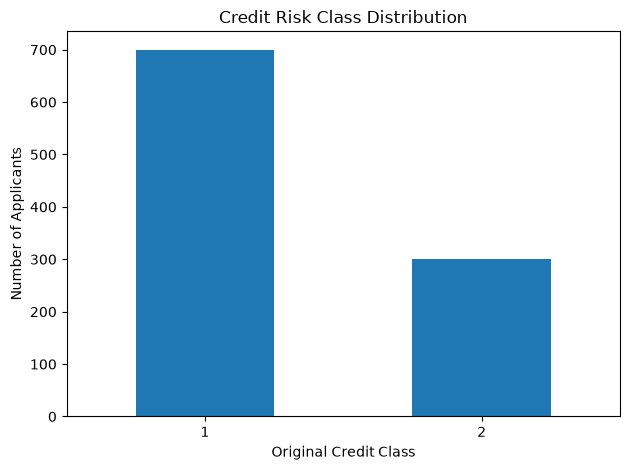

In [5]:
import matplotlib.pyplot as plt

class_counts = df["class"].value_counts().sort_index()

class_counts.plot(kind="bar", rot=0)

plt.title("Credit Risk Class Distribution")
plt.xlabel("Original Credit Class")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.show()

In [6]:

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Count each credit class
print("\nCredit class counts:")
print(df["class"].value_counts().sort_index())

# Calculate percentages
print("\nCredit class percentages:")
print(
    (df["class"].value_counts(normalize=True).sort_index() * 100).round(2)
)

Duplicate rows: 0

Credit class counts:
class
1    700
2    300
Name: count, dtype: int64

Credit class percentages:
class
1    70.0
2    30.0
Name: proportion, dtype: float64


In [7]:

# Display the feature names
print("Feature names:")
print(X.columns.tolist())

# Display the first five rows
print("\nFirst five rows:")
display(df.head())

# Display the data type of every column
print("\nColumn data types:")
print(df.dtypes)

# Display a sample of unique values
print("\nUnique values in each feature:")
for column in X.columns:
    print(f"{column}: {X[column].unique()[:8]}")

Feature names:
['Attribute1', 'Attribute2', 'Attribute3', 'Attribute4', 'Attribute5', 'Attribute6', 'Attribute7', 'Attribute8', 'Attribute9', 'Attribute10', 'Attribute11', 'Attribute12', 'Attribute13', 'Attribute14', 'Attribute15', 'Attribute16', 'Attribute17', 'Attribute18', 'Attribute19', 'Attribute20']

First five rows:


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,...,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20,class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2



Column data types:
Attribute1       str
Attribute2     int64
Attribute3       str
Attribute4       str
Attribute5     int64
Attribute6       str
Attribute7       str
Attribute8     int64
Attribute9       str
Attribute10      str
Attribute11    int64
Attribute12      str
Attribute13    int64
Attribute14      str
Attribute15      str
Attribute16    int64
Attribute17      str
Attribute18    int64
Attribute19      str
Attribute20      str
class          int64
dtype: object

Unique values in each feature:
Attribute1: <StringArray>
['A11', 'A12', 'A14', 'A13']
Length: 4, dtype: str
Attribute2: [ 6 48 12 42 24 36 30 15]
Attribute3: <StringArray>
['A34', 'A32', 'A33', 'A30', 'A31']
Length: 5, dtype: str
Attribute4: <StringArray>
['A43', 'A46', 'A42', 'A40', 'A41', 'A49', 'A44', 'A45']
Length: 8, dtype: str
Attribute5: [1169 5951 2096 7882 4870 9055 2835 6948]
Attribute6: <StringArray>
['A65', 'A61', 'A63', 'A64', 'A62']
Length: 5, dtype: str
Attribute7: <StringArray>
['A75', 'A73', 'A74', 'A7

In [9]:

# Display the official dataset feature descriptions

variables = credit_data.variables

display(
    variables[["name", "description", "role", "type"]]
)

,name,description,role,type
0,Attribute1,Status of existing checking account,Feature,Categorical
1,Attribute2,Duration,Feature,Integer
2,Attribute3,Credit history,Feature,Categorical
3,Attribute4,Purpose,Feature,Categorical
4,Attribute5,Credit amount,Feature,Integer
5,Attribute6,Savings account/bonds,Feature,Categorical
6,Attribute7,Present employment since,Feature,Categorical
7,Attribute8,Installment rate in percentage of disposable i...,Feature,Integer
8,Attribute9,Personal status and sex,Feature,Categorical
9,Attribute10,Other debtors / guarantors,Feature,Categorical


In [10]:

variables = credit_data.variables

for _, row in variables.iterrows():
    print(f"{row['name']}: {row['description']}")

Attribute1: Status of existing checking account
Attribute2: Duration
Attribute3: Credit history
Attribute4: Purpose
Attribute5: Credit amount
Attribute6: Savings account/bonds
Attribute7: Present employment since
Attribute8: Installment rate in percentage of disposable income
Attribute9: Personal status and sex
Attribute10: Other debtors / guarantors
Attribute11: Present residence since
Attribute12: Property
Attribute13: Age
Attribute14: Other installment plans
Attribute15: Housing
Attribute16: Number of existing credits at this bank
Attribute17: Job
Attribute18: Number of people being liable to provide maintenance for
Attribute19: Telephone
Attribute20: foreign worker
class: 1 = Good, 2 = Bad


In [2]:

from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the German Credit dataset
credit_data = fetch_ucirepo(id=144)

X = credit_data.data.features.copy()
y_original = credit_data.data.targets.iloc[:, 0]

# Create the working dataframe
df = X.copy()
df["class"] = y_original

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (1000, 21)


In [3]:

# Input features
X = df.drop(columns=["class"])

# Target: 1 = bad credit, 0 = good credit
y = (df["class"] == 2).astype(int)

# Split into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training input shape:", X_train.shape)
print("Testing input shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())


Training input shape: (800, 20)
Testing input shape: (200, 20)

Training target distribution:
class
0    560
1    240
Name: count, dtype: int64

Testing target distribution:
class
0    140
1     60
Name: count, dtype: int64


In [4]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

# Identify categorical and numerical columns
categorical_cols = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Number of categorical columns:", len(categorical_cols))

print("\nNumerical columns:", numerical_cols)
print("Number of numerical columns:", len(numerical_cols))

# Prepare numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preparation steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numerical_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Build the complete model pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

print("\nData preparation and model pipeline created successfully!")


Categorical columns: ['Attribute1', 'Attribute3', 'Attribute4', 'Attribute6', 'Attribute7', 'Attribute9', 'Attribute10', 'Attribute12', 'Attribute14', 'Attribute15', 'Attribute17', 'Attribute19', 'Attribute20']
Number of categorical columns: 13

Numerical columns: ['Attribute2', 'Attribute5', 'Attribute8', 'Attribute11', 'Attribute13', 'Attribute16', 'Attribute18']
Number of numerical columns: 7

Data preparation and model pipeline created successfully!


In [5]:

# Train the model using 800 training records
model.fit(X_train, y_train)

print("Model trained successfully!")

# Predict credit risk for 200 unseen test records
y_pred = model.predict(X_test)

print("Predictions completed!")

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred[:10].tolist())


Model trained successfully!
Predictions completed!

First 10 actual labels:
[0, 0, 1, 0, 1, 0, 0, 0, 0, 0]

First 10 predicted labels:
[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]


MODEL EVALUATION RESULTS
------------------------------
Accuracy:  78.00%
Precision: 66.67%
Recall:    53.33%
F1-score:  59.26%

Classification Report:
              precision    recall  f1-score   support

 Good credit       0.82      0.89      0.85       140
  Bad credit       0.67      0.53      0.59        60

    accuracy                           0.78       200
   macro avg       0.74      0.71      0.72       200
weighted avg       0.77      0.78      0.77       200

Confusion Matrix:
[[124  16]
 [ 28  32]]


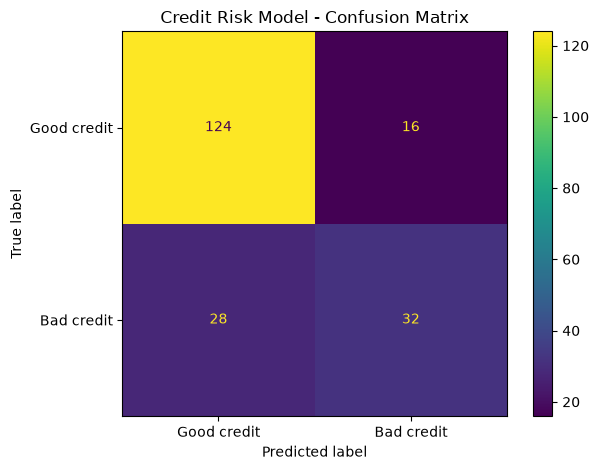

In [6]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("MODEL EVALUATION RESULTS")
print("-" * 30)
print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1-score:  {f1:.2%}")

# Detailed results
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Good credit", "Bad credit"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print("Confusion Matrix:")
print(cm)

# Visualize the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Good credit", "Bad credit"]
).plot()
plt.title("Credit Risk Model - Confusion Matrix")
plt.tight_layout()
plt.show()


In [8]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Create and train the balanced model
balanced_model = clone(model)
balanced_model.set_params(classifier__class_weight="balanced")
balanced_model.fit(X_train, y_train)

# Make predictions
y_pred_balanced = balanced_model.predict(X_test)

# Compare both models
print("MODEL COMPARISON")
print("-" * 55)
print(f"{'Metric':<15}{'Original':>15}{'Balanced':>15}")
print("-" * 55)

metrics = [
    ("Accuracy", accuracy_score),
    ("Precision", precision_score),
    ("Recall", recall_score),
    ("F1-score", f1_score)
]

for name, metric in metrics:
    original = metric(y_test, y_pred) if name == "Accuracy" else metric(y_test, y_pred, zero_division=0)
    balanced = metric(y_test, y_pred_balanced) if name == "Accuracy" else metric(y_test, y_pred_balanced, zero_division=0)

    print(f"{name:<15}{original:>14.2%}{balanced:>14.2%}")


MODEL COMPARISON
-------------------------------------------------------
Metric                Original       Balanced
-------------------------------------------------------
Accuracy               78.00%        75.00%
Precision              66.67%        55.81%
Recall                 53.33%        80.00%
F1-score               59.26%        65.75%


Balanced Model Confusion Matrix:
[[102  38]
 [ 12  48]]


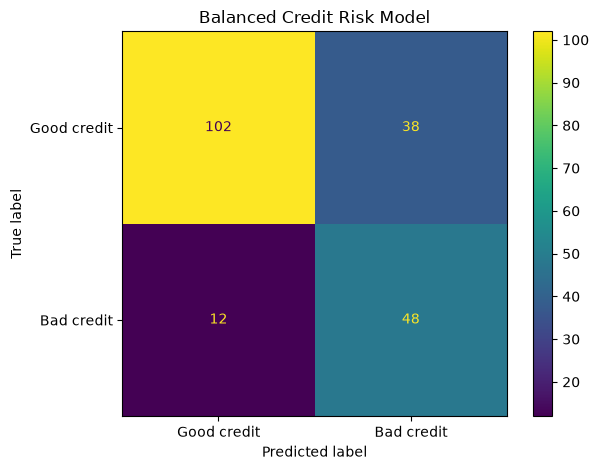

In [9]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm_balanced = confusion_matrix(
    y_test,
    y_pred_balanced,
    labels=[0, 1]
)

print("Balanced Model Confusion Matrix:")
print(cm_balanced)

ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Good credit", "Bad credit"]
).plot()

plt.title("Balanced Credit Risk Model")
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = pd.DataFrame({
    "Model": ["Original Logistic Regression",
              "Balanced Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_balanced, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_balanced, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_balanced, zero_division=0)
    ]
})

print(results.round(3).to_string(index=False))

                       Model  Accuracy  Precision  Recall  F1-score
Original Logistic Regression      0.78      0.667   0.533     0.593
Balanced Logistic Regression      0.75      0.558   0.800     0.658


In [11]:
results.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!


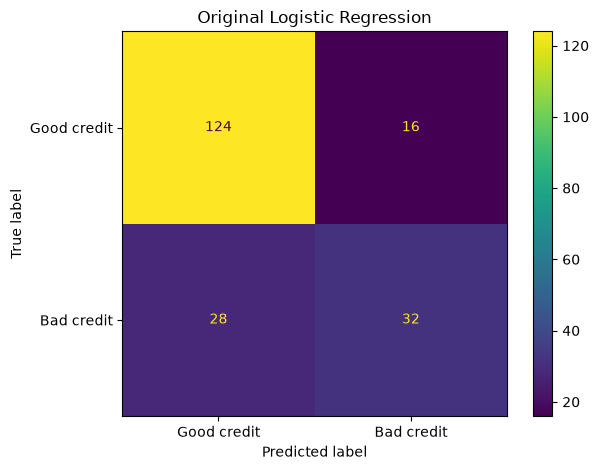

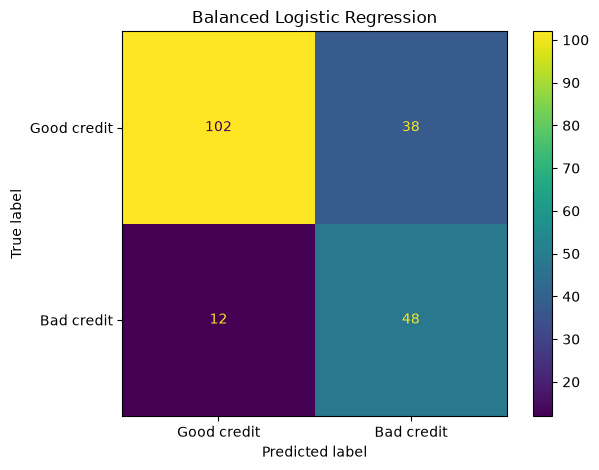

Both confusion matrix images saved successfully!


In [12]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import os

# Create a folder for project images
os.makedirs("images", exist_ok=True)

# Original model confusion matrix
cm_original = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_original,
    display_labels=["Good credit", "Bad credit"]
)
disp.plot()
plt.title("Original Logistic Regression")
plt.tight_layout()
plt.savefig("images/original_confusion_matrix.png", dpi=300)
plt.show()
plt.close()

# Balanced model confusion matrix
cm_balanced = confusion_matrix(
    y_test, y_pred_balanced, labels=[0, 1]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_balanced,
    display_labels=["Good credit", "Bad credit"]
)
disp.plot()
plt.title("Balanced Logistic Regression")
plt.tight_layout()
plt.savefig("images/balanced_confusion_matrix.png", dpi=300)
plt.show()
plt.close()

print("Both confusion matrix images saved successfully!")